# Coding Project 1: Linear Regression and Regularization

**Group members:**

Giulio Tonielli, Isabella Ceotto, Zhenbin Marco Fu, Ariba Mbeche


### Question 1 - Importing and Preparing the Data

X shape: (1460, 79)
y shape: (1460,)


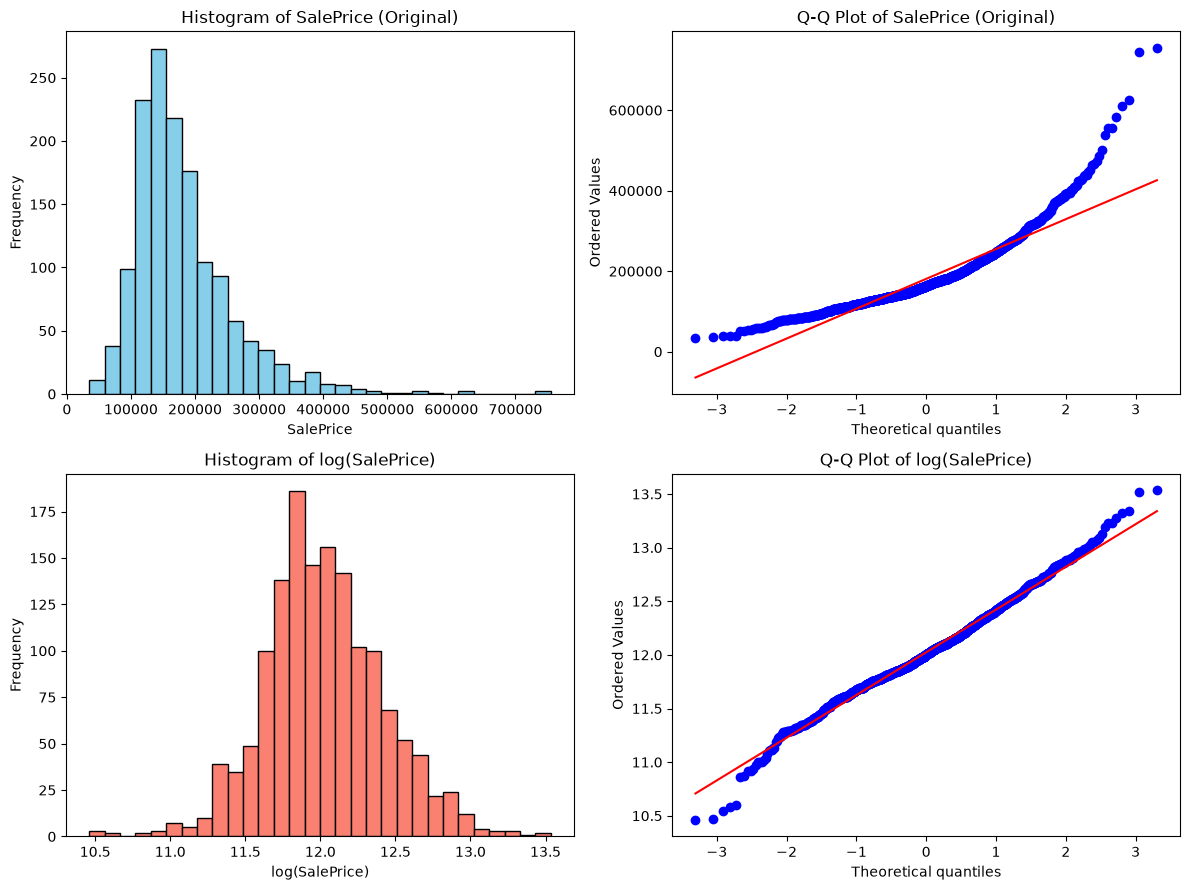

Original SalePrice Skewness: 1.883
Log-transformed SalePrice Skewness: 0.121


In [16]:
# For Question 1, you may find the following packages useful:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import scipy.stats as stats
from sklearn.model_selection import train_test_split

# 1.a) Import Housing.csv as a pandas DataFrame.
# Separate the explanatory features X from the target y = SalePrice.
#
# Guidance:
# - Refer to data_description.txt to determine how variables should be interpreted.
# - The first column of the csv file is an index and should not be used as an explanatory variable.
# - Keep the original variable names so that later coefficient tables are easy to interpret.


# Load the raw dataset; blank CSV fields become missing values, while literal labels are preserved.
df = pd.read_csv("Housing.csv", index_col=0, keep_default_na=False, na_values=[""])

y = df["SalePrice"]
X = df.drop(columns=["SalePrice"])

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")


# 1.b) Graphically determine whether SalePrice is approximately Gaussian.
# If it is not, suggest and apply a suitable transformation.
# Explain why considering such a transformation can be important.
#
# Guidance:
# - Use suitable graphical diagnostics (for example, a histogram and/or Q-Q plot).
# - Keep track of the transformation you choose because later questions require metrics
#   both on the transformed scale and, after inverse transformation, on the original
#   SalePrice scale.

# Graphical diagnostics for raw SalePrice
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# Original SalePrice Histogram & Q-Q Plot
axes[0, 0].hist(y, bins=30, color='skyblue', edgecolor='black')
axes[0, 0].set_title("Histogram of SalePrice (Original)")
axes[0, 0].set_xlabel("SalePrice")
axes[0, 0].set_ylabel("Frequency")

stats.probplot(y, dist="norm", plot=axes[0, 1])
axes[0, 1].set_title("Q-Q Plot of SalePrice (Original)")

# Apply log transformation
y_log = np.log(y)

# Transformed log(SalePrice) Histogram & Q-Q Plot
axes[1, 0].hist(y_log, bins=30, color='salmon', edgecolor='black')
axes[1, 0].set_title("Histogram of log(SalePrice)")
axes[1, 0].set_xlabel("log(SalePrice)")
axes[1, 0].set_ylabel("Frequency")

stats.probplot(y_log, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Q-Q Plot of log(SalePrice)")

plt.tight_layout()
plt.show()

print(f"Original SalePrice Skewness: {y.skew():.3f}")
print(f"Log-transformed SalePrice Skewness: {y_log.skew():.3f}")

### 1.b — Distribution of SalePrice

The raw `SalePrice` is clearly right-skewed, with a heavy upper tail (skewness $1.883$), and
its Q-Q plot bends upwards in the upper quantiles: the distribution is not Gaussian.

Taking the natural logarithm reduces the skewness to $0.121$. The histogram of
$\log(\text{SalePrice})$ is approximately symmetric and its Q-Q plot lies close to the
reference line, so we model $\log(\text{SalePrice})$ from now on.

Why the transformation matters:

* OLS is the best linear unbiased estimator under the Gauss–Markov assumptions (linearity,
  exogeneity, homoscedastic and uncorrelated errors). These assumptions do **not** require
  normal errors; normality is only needed for exact finite-sample inference (t-tests,
  F-tests and confidence intervals), such as the standard errors computed in 2.b.
* With a right-skewed price, prediction errors tend to grow proportionally with the price
  level, which violates homoscedasticity. The log transform stabilises the residual
  variance and brings the residuals closer to normality, so the inference is more credible.
* The few very expensive houses have a large influence on a fit in dollars; on the log
  scale their leverage is much smaller.
* Coefficients become approximate relative (percentage) effects instead of absolute dollar
  effects.

Because metrics are also required on the original scale, predictions are mapped back with
$\exp(\cdot)$ whenever needed.

In [17]:
# 1.c) Split the data into training and test sets.
# Randomly assign 70% of the observations to the training set and 30% to the test set.
#
# IMPORTANT:
# - Save an UNPROCESSED copy of X_train and X_test before doing any imputation,
#   standardization, or one-hot encoding.
# - You will return to these raw splits in Question 3.b) to build a leakage-safe
#   cross-validation pipeline.
#
# Suggested naming:
# X_train_raw, X_test_raw, y_train, y_test

# train_test_split shuffles by default and applies the same split to each input,
# keeping features and both target versions paired; test_size=0.30 reserves 30% for testing.
# random_state makes the split reproducible.
(
    X_train_raw,
    X_test_raw,

    y_train_log,
    y_test_log,
    
    y_train_original,
    y_test_original,
) = train_test_split(
    X,
    y_log,
    y,
    test_size=0.30,
    random_state=42,
)

# Use the transformed target for regression and retain original prices for evaluation.
y_train = y_train_log
y_test = y_test_log

### 1.c Explanation

In 1.a, we separated the explanatory features from `SalePrice`; in 1.b, we used the natural log of `SalePrice` because it was less right-skewed. Here, we made a reproducible 70/30 train/test split, keeping the log target for model fitting and the original prices for evaluation on the dollar scale. The feature splits remain unprocessed so preprocessing can be fitted only on training data later, avoiding leakage into the test set and cross-validation folds.

In [18]:
# 1.d) Replace missing values in X using the training data statistics only.
#
# NOTE: Some categorical variables admit 'NA' (or 'None') as a valid category, which should be
#   treated as an actual level and not as missing.
valid_na_categories = {
    "Alley", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
    "FireplaceQu", "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "PoolQC", "Fence", "MiscFeature",
}
valid_none_categories = {"MasVnrType"}


def clean_raw_features(X):
    """Turn undocumented 'NA' / 'None' labels into missing values (no statistics are fitted)."""
    X = X.copy()
    for column in X.columns:
        if column not in valid_na_categories:
            X[column] = X[column].replace("NA", np.nan)
        if column not in valid_none_categories:
            X[column] = X[column].replace("None", np.nan)
    for column in ("LotFrontage", "MasVnrArea", "GarageYrBlt"):
        X[column] = pd.to_numeric(X[column])
    return X


X_train = clean_raw_features(X_train_raw)
X_test = clean_raw_features(X_test_raw)

# NOTE: MSSubClass is categorical in the data description, although it is stored as a number.
categorical_columns = [
    column for column in X_train.columns
    if not pd.api.types.is_numeric_dtype(X_train[column])
]
categorical_columns.append("MSSubClass")
numeric_columns = [column for column in X_train.columns if column not in categorical_columns]

# - For numerical features, replace missing values with the training mean of the column.
numeric_means = X_train[numeric_columns].mean()
X_train[numeric_columns] = X_train[numeric_columns].fillna(numeric_means)
X_test[numeric_columns] = X_test[numeric_columns].fillna(numeric_means)

# - For categorical features, replace missing values with the training mode of the column.
categorical_modes = X_train[categorical_columns].mode(dropna=True).iloc[0]
X_train[categorical_columns] = X_train[categorical_columns].fillna(categorical_modes)
X_test[categorical_columns] = X_test[categorical_columns].fillna(categorical_modes)

# Next, standardize all numerical features with a z-score transform using the training
# mean and standard deviation, and apply the same transformation to the test data.
# Finally, one-hot encode all categorical features and align the test columns with the
# training columns.
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train[numeric_columns] = scaler.fit_transform(X_train[numeric_columns])
X_test[numeric_columns] = scaler.transform(X_test[numeric_columns])

X_train = pd.get_dummies(X_train, columns=categorical_columns, dtype=int)
X_test = pd.get_dummies(X_test, columns=categorical_columns, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print(f"Prepared training matrix: {X_train.shape}, test matrix: {X_test.shape}")

Prepared training matrix: (1022, 311), test matrix: (438, 311)


### 1.d Explanation

The preprocessing starts from copies of the raw train and test features, leaving the raw
splits available for the cross-validation in Question 3. The function `clean_raw_features`
interprets `"NA"` and `"None"` according to the data description: documented category labels
remain values, while other occurrences are treated as missing. Numeric columns that contain
these labels are converted back to numbers so they receive numerical rather than
categorical processing. The same function is reused inside the Question 3 pipelines.

For imputation, each numerical training-column mean and each categorical training-column
mode is learned from the training split and then reused to fill the test split, so no
test-set statistic is used.

For numerical standardization, `StandardScaler.fit_transform` learns each feature's mean and
population standard deviation from the imputed training set (`ddof=0`) and applies the
z-score

$$z = \frac{x - \mu_{\text{train}}}{\sigma_{\text{train}}}.$$

`StandardScaler.transform` applies the same training-set values to the test set. Each
transformed training feature therefore has mean zero and standard deviation one, and the
test features are measured on the same training-based scale.

Finally, `pd.get_dummies` converts the categorical values into indicator columns. Since a
category may occur in one split but not in the other, reindexing the test set to the
training columns fills absent categories with zero and guarantees identical columns in
identical order.

### Question 2 - Linear Regression on Numerical Features

In [19]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import statsmodels.api as sm


def evaluate(model, X, y_log):
    """MSE and R^2 on the log scale and, after exp(), on the original SalePrice scale."""
    pred_log = model.predict(X)
    y_price, pred_price = np.exp(y_log), np.exp(pred_log)
    return {
        "MSE (log)": mean_squared_error(y_log, pred_log),
        "R² (log)": r2_score(y_log, pred_log),
        "MSE (price)": mean_squared_error(y_price, pred_price),
        "R² (price)": r2_score(y_price, pred_price),
    }


# 2.a) Fit an OLS regression using ONLY the numerical predictors and sklearn.
# Include an intercept.
X_train_num = X_train[numeric_columns]
X_test_num = X_test[numeric_columns]

ols_num = LinearRegression(fit_intercept=True)
ols_num.fit(X_train_num, y_train)

# Required output:
# - A table with each numerical feature and its estimated regression coefficient.
feature_names = ['Intercept'] + list(X_train_num.columns)
sklearn_coefs = np.insert(ols_num.coef_, 0, ols_num.intercept_)

print("--- Estimated Coefficients (OLS with only numerical features) ---")
display(pd.DataFrame({'Feature': feature_names, 'Coefficient': sklearn_coefs}))

# - In-sample and out-of-sample MSE and R^2, on the transformed (log) scale and on the
#   original SalePrice scale after inverse-transforming the predictions.
metrics_num_train = evaluate(ols_num, X_train_num, y_train)
metrics_num_test = evaluate(ols_num, X_test_num, y_test)

print("\n--- Model Performance Summary ---")
display(pd.DataFrame({"Training": metrics_num_train, "Test": metrics_num_test}).T)

--- Estimated Coefficients (OLS with only numerical features) ---


,Feature,Coefficient
0,Intercept,12.028893
1,LotFrontage,-0.001184
2,LotArea,0.021449
3,OverallQual,0.114283
4,OverallCond,0.047926
5,YearBuilt,0.091382
6,YearRemodAdd,0.027551
7,MasVnrArea,-0.006479
8,BsmtFinSF1,0.009722
9,BsmtFinSF2,0.001543



--- Model Performance Summary ---


,MSE (log),R² (log),MSE (price),R² (price)
Training,0.021996,0.858098,1.433794e+09,0.761772
Test,0.021870,0.871086,8.291143e+08,0.881183


### 2.a — OLS on numerical predictors

We restrict the analysis to the 35 numerical predictors and fit an OLS regression with an
intercept on the training set.

Because the predictors are $z$-score standardized and the target is $\log(\text{SalePrice})$,
each coefficient $\hat{\beta}_j$ is a semi-elasticity: holding the other variables fixed, a
one-standard-deviation increase in feature $j$ is associated with an approximate
$\hat{\beta}_j \times 100\%$ change in price, or exactly $(e^{\hat{\beta}_j}-1)\times 100\%$.

The intercept $\hat{\beta}_0 \approx 12.029$ is the predicted log-price when every
standardized predictor equals its training mean, i.e. $\exp(12.029) \approx \$167{,}525$.
Under log-normal errors this is the predicted conditional median, not the mean.

The largest positive effects are `OverallQual` ($+11.4\%$), `YearBuilt` ($+9.1\%$),
`GarageCars` ($+6.0\%$), `OverallCond` ($+4.8\%$) and `GrLivArea` ($+4.6\%$). The main
negative associations are `KitchenAbvGr` ($-2.4\%$) and `PoolArea` ($-2.1\%$). Several
floor and basement area variables are exactly collinear (see 2.b), so their individual
coefficients should be interpreted with caution.

#### Model performance

| Set | MSE (log) | $R^2$ (log) | MSE (price) | $R^2$ (price) |
| --- | --: | --: | --: | --: |
| Training | 0.021996 | 0.858098 | $1.43\times10^{9}$ | 0.761772 |
| Test     | 0.021870 | 0.871086 | $8.29\times10^{8}$ | 0.881183 |

On the log scale training and test performance are close ($R^2 = 0.858$ vs $0.871$; MSE
$\approx 0.022$, i.e. an RMSE of about $0.148$ log points, roughly $15\%$ of the price). This
indicates good generalization with no sign of overfitting; the slightly higher test $R^2$ is
within the sampling variability of a single split. On the original scale the test RMSE is
about $\$28{,}800$.

The two scales answer different questions and their $R^2$ values are not directly
comparable, because each measures explained variance relative to a different baseline
(the variance of $\log(\text{price})$ vs the variance of the price):

1. On the original scale the squared error is in dollars², so it is dominated by expensive
   houses. The original-scale metrics are therefore very sensitive to the few extreme
   properties in each split. The training set contains the well-known Ames outliers (very
   large houses sold at low prices, see 3.a), which explains why the training $R^2$
   ($0.762$) is much lower than the test $R^2$ ($0.881$) on this scale only.
2. Back-transforming with $\exp(\hat{y})$ estimates the conditional median, not the mean, so
   it slightly under-predicts on the original scale; under log-normal errors the correction
   would be $\exp(\hat{y} + \hat{\sigma}^2/2)$.
3. The log scale is the scale on which the model is fitted and on which the errors are
   approximately homoscedastic, so the log-scale metrics are the more reliable summary of
   model quality. The original-scale metrics measure the error in dollars, which is the
   relevant quantity for a buyer or a seller.

### 2.b — OLS by matrix algebra

We reproduce the OLS estimator with matrix algebra on the training set and study the
numerical structure of the design matrix $A \in \mathbb{R}^{1022\times 36}$ ($m = 1022$
observations, $d+1 = 36$ parameters), obtained by prepending a column of ones to the 35
standardized numerical predictors.

In [20]:
# 2.b) Reproduce and investigate OLS using matrix algebra on the TRAINING SET ONLY.
#
# Let A denote the design matrix containing the numerical predictors plus a column
# of ones for the intercept.
A = np.column_stack([np.ones(X_train_num.shape[0]), X_train_num.values])
y_tr = y_train.values
m = A.shape[0]            # number of training observations
d = X_train_num.shape[1]  # number of predictors (d + 1 parameters with the intercept)
n_cols = d + 1

# (i) Compute the estimated coefficients using numpy.
#     Use a numerically stable linear-system solver such as np.linalg.solve(...)
#     whenever the system is numerically well behaved; do not explicitly form
#     a matrix inverse merely to solve the normal equations.
ATA = A.T @ A
beta_solve = np.linalg.solve(ATA, A.T @ y_tr)

#     Expected output:
#     - Estimated intercept and feature coefficients.
#     - A comparison with the sklearn estimates from Question 2.a).
comparison_solve = pd.DataFrame({
    'Feature': feature_names,
    'NumPy (normal equations)': beta_solve,
    'scikit-learn': sklearn_coefs,
    'Absolute Difference': np.abs(beta_solve - sklearn_coefs)
})
print("--- Normal equations (np.linalg.solve) vs scikit-learn ---")
display(comparison_solve)
print(f"Coefficients coincide within tolerance? {np.allclose(beta_solve, sklearn_coefs)}")
print(f"Maximum absolute difference in beta: {np.max(np.abs(beta_solve - sklearn_coefs)):.4e}")
print(f"Maximum absolute difference in fitted values: "
      f"{np.max(np.abs(A @ beta_solve - ols_num.predict(X_train_num))):.4e}")

# The normal equations are unreliable here (see (iv)), so we use the SVD-based
# least-squares solver, which returns the minimum-norm solution as sklearn does.
beta_svd, _, _, _ = np.linalg.lstsq(A, y_tr, rcond=None)

comparison_svd = pd.DataFrame({
    'Feature': feature_names,
    'NumPy (SVD / lstsq)': beta_svd,
    'scikit-learn': sklearn_coefs,
    'Absolute Difference': np.abs(beta_svd - sklearn_coefs)
})
print("\n--- SVD least squares (np.linalg.lstsq) vs scikit-learn ---")
print(comparison_svd.to_string(index=False))
print(f"\nCoefficients coincide within tolerance? {np.allclose(beta_svd, sklearn_coefs)}")
print(f"Maximum absolute difference in beta: {np.max(np.abs(beta_svd - sklearn_coefs)):.4e}")

--- Normal equations (np.linalg.solve) vs scikit-learn ---


,Feature,NumPy (normal equations),scikit-learn,Absolute Difference
0,Intercept,12.028893,12.028893,1.776357e-15
1,LotFrontage,-0.001184,-0.001184,2.337540e-16
2,LotArea,0.021449,0.021449,1.526557e-16
3,OverallQual,0.114283,0.114283,7.077672e-16
4,OverallCond,0.047926,0.047926,1.068590e-15
5,YearBuilt,0.091382,0.091382,3.219647e-15
6,YearRemodAdd,0.027551,0.027551,6.938894e-17
7,MasVnrArea,-0.006479,-0.006479,9.228729e-16
8,BsmtFinSF1,0.963132,0.009722,9.534104e-01
9,BsmtFinSF2,0.314966,0.001543,3.134233e-01


Coefficients coincide within tolerance? False
Maximum absolute difference in beta: 9.5341e-01
Maximum absolute difference in fitted values: 4.6185e-14

--- SVD least squares (np.linalg.lstsq) vs scikit-learn ---
      Feature  NumPy (SVD / lstsq)  scikit-learn  Absolute Difference
    Intercept            12.028893     12.028893         7.105427e-15
  LotFrontage            -0.001184     -0.001184         1.949612e-15
      LotArea             0.021449      0.021449         3.104461e-14
  OverallQual             0.114283      0.114283         1.332268e-15
  OverallCond             0.047926      0.047926         1.033895e-14
    YearBuilt             0.091382      0.091382         5.881406e-14
 YearRemodAdd             0.027551      0.027551         1.442943e-14
   MasVnrArea            -0.006479     -0.006479         8.149731e-15
   BsmtFinSF1             0.009722      0.009722         2.359224e-16
   BsmtFinSF2             0.001543      0.001543         8.332527e-15
    BsmtUnfSF     

#### (i) Coefficients: normal equations vs SVD

We first solve the normal equations $(A^\top A)\hat\beta = A^\top y$ with `np.linalg.solve`,
as prescribed, and then show why this route is unreliable for this design matrix.

$A$ is rank-deficient: it has 36 columns but numerical rank 34, because two exact linear
identities hold among the area variables:
$$\text{TotalBsmtSF} = \text{BsmtFinSF1} + \text{BsmtFinSF2} + \text{BsmtUnfSF},$$
$$\text{GrLivArea} = \text{1stFlrSF} + \text{2ndFlrSF} + \text{LowQualFinSF}.$$
Both identities survive $z$-score standardization, which is an affine column-wise map, and
they create a two-dimensional null space. As a result
$\kappa(A) \approx 9.66\times10^{15}$ and, after forming the normal equations,
$\kappa(A^\top A) \approx 4.60\times10^{16}$, beyond the resolution of double precision.

`np.linalg.solve` raises no error, but its output is unreliable. The 28 non-collinear
coefficients agree with scikit-learn to $\sim10^{-15}$, while the 8 coefficients involved in
the identities are essentially arbitrary, differing by up to $0.953$ (e.g. `BsmtFinSF1`
$= 0.963$ vs $0.0097$; `TotalBsmtSF` $= -0.915$ vs $0.0127$), so `np.allclose` returns
`False`. These discrepancies lie in the null space of $A$ and are annihilated by it: the
fitted values still agree with scikit-learn to $4.6\times10^{-14}$. The instability therefore
corrupts the individual, non-identified coefficients without affecting the fit.

Since the least-squares problem has infinitely many solutions, we use the SVD-based solver
`np.linalg.lstsq(A, y, rcond=None)`, which discards the singular values below machine
precision and returns the unique minimum-$\ell_2$-norm solution. This is the same LAPACK
routine (`gelsd`) used by scikit-learn, and the two agree to machine precision on all 36
coefficients (max abs. difference $7.1\times10^{-14}$; `np.allclose` → `True`). The
mismatch obtained with `solve` is thus a consequence of the exact collinearity, not a coding
error.

In [21]:
# (ii) Compute the standard error of each estimated coefficient using numpy.
#
#      Expected output:
#      - A table containing coefficient estimates and their standard errors,
#        including the intercept.
#      - Clearly state which estimate corresponds to the intercept.
residuals = y_tr - A @ beta_svd
rss = np.sum(residuals**2)
sigma2_hat = rss / (m - (d + 1))

# (A^T A)^+ = A^+ (A^+)^T avoids forming A^T A and squaring the condition number.
pinv_A = np.linalg.pinv(A)
cov_beta = sigma2_hat * (pinv_A @ pinv_A.T)
se_svd = np.sqrt(np.maximum(np.diag(cov_beta), 0.0))

se_table = pd.DataFrame({
    'j': np.arange(n_cols),
    'Parameter': ['Intercept (beta_0)'] + list(X_train_num.columns),
    'Coefficient (beta_hat)': beta_svd,
    'Std. Error': se_svd
})
print("--- Question 2.b (ii): Coefficients and Standard Errors ---")
print(f"sigma^2_hat = {sigma2_hat:.6f}  (dof = m - (d+1) = {m - (d + 1)})")
print(f"j = 0 is the intercept: beta_0 = {beta_svd[0]:.6f}, SE = {se_svd[0]:.6f}\n")
print(se_table.to_string(index=False))

--- Question 2.b (ii): Coefficients and Standard Errors ---
sigma^2_hat = 0.022799  (dof = m - (d+1) = 986)
j = 0 is the intercept: beta_0 = 12.028893, SE = 0.004723

 j          Parameter  Coefficient (beta_hat)  Std. Error
 0 Intercept (beta_0)               12.028893    0.004723
 1        LotFrontage               -0.001184    0.005665
 2            LotArea                0.021449    0.005315
 3        OverallQual                0.114283    0.008458
 4        OverallCond                0.047926    0.005955
 5          YearBuilt                0.091382    0.010838
 6       YearRemodAdd                0.027551    0.007464
 7         MasVnrArea               -0.006479    0.005630
 8         BsmtFinSF1                0.009722    0.005301
 9         BsmtFinSF2                0.001543    0.004891
10          BsmtUnfSF                0.002210    0.004705
11        TotalBsmtSF                0.012719    0.006580
12           1stFlrSF                0.039104    0.007821
13           2ndFlrSF

#### (ii) Standard errors

From the SVD-fit residuals we compute
$$\hat{\sigma}^2 = \frac{1}{m-(d+1)}\sum_{i=1}^m (y_i-\hat{y}_i)^2 = 0.022799,\qquad
\text{SE}(\hat{\beta}_j)=\sqrt{\hat{\sigma}^2\,[(A^\top A)^{+}]_{jj}},$$
with $m-(d+1)=986$ degrees of freedom, as in the formula of the assignment. Because
$A^\top A$ is singular, its inverse is replaced by the pseudoinverse, evaluated without
forming $A^\top A$ through the identity $(A^\top A)^{+}=A^{+}(A^{+})^\top$.

The row $j = 0$ is the intercept: $\hat{\beta}_0 = 12.028893$ with $\text{SE} = 0.004723$.

| $j$ | Parameter | $\hat{\beta}_j$ | SE |
| --: | --- | --: | --: |
| 0 | **Intercept** | 12.028893 | 0.004723 |
| 1 | LotFrontage | -0.001184 | 0.005665 |
| 2 | LotArea | 0.021449 | 0.005315 |
| 3 | OverallQual | 0.114283 | 0.008458 |
| 4 | OverallCond | 0.047926 | 0.005955 |
| 5 | YearBuilt | 0.091382 | 0.010838 |
| 6 | YearRemodAdd | 0.027551 | 0.007464 |
| 7 | MasVnrArea | -0.006479 | 0.005630 |
| 8 | BsmtFinSF1 *(collinear)* | 0.009722 | 0.005301 |
| 9 | BsmtFinSF2 *(collinear)* | 0.001543 | 0.004891 |
| 10 | BsmtUnfSF *(collinear)* | 0.002210 | 0.004705 |
| 11 | TotalBsmtSF *(collinear)* | 0.012719 | 0.006580 |
| 12 | 1stFlrSF *(collinear)* | 0.039104 | 0.007821 |
| 13 | 2ndFlrSF *(collinear)* | 0.019676 | 0.006565 |
| 14 | LowQualFinSF *(collinear)* | 0.005416 | 0.005039 |
| 15 | GrLivArea *(collinear)* | 0.045524 | 0.007117 |
| 16 | BsmtFullBath | 0.034180 | 0.007022 |
| 17 | BsmtHalfBath | 0.003011 | 0.005162 |
| 18 | FullBath | 0.016298 | 0.008023 |
| 19 | HalfBath | 0.011656 | 0.006850 |
| 20 | BedroomAbvGr | 0.006727 | 0.007392 |
| 21 | KitchenAbvGr | -0.024321 | 0.005641 |
| 22 | TotRmsAbvGrd | 0.030190 | 0.010646 |
| 23 | Fireplaces | 0.033555 | 0.005956 |
| 24 | GarageYrBlt | -0.011866 | 0.008584 |
| 25 | GarageCars | 0.059897 | 0.010982 |
| 26 | GarageArea | 0.011731 | 0.011024 |
| 27 | WoodDeckSF | 0.015830 | 0.005256 |
| 28 | OpenPorchSF | -0.004765 | 0.005189 |
| 29 | EnclosedPorch | 0.012223 | 0.005433 |
| 30 | 3SsnPorch | 0.010648 | 0.004793 |
| 31 | ScreenPorch | 0.021187 | 0.005046 |
| 32 | PoolArea | -0.020668 | 0.005203 |
| 33 | MiscVal | -0.004047 | 0.004900 |
| 34 | MoSold | 0.005630 | 0.004860 |
| 35 | YrSold | -0.004117 | 0.004870 |

For the 8 collinear variables the coefficients are not identified: the minimum-norm
solution assigns them finite values and finite SEs, but these SEs describe the precision of
that particular minimum-norm combination, not the classical precision of each individual
effect.

In [22]:
# (iii) Using your matrix-algebra implementation, verify that the in-sample
#       MSE and R^2 agree with the corresponding results from Question 2.a),
#       up to numerical rounding.
mse_in_sample_manual = rss / m
r2_in_sample_manual = 1.0 - rss / np.sum((y_tr - np.mean(y_tr))**2)
mse_sklearn = metrics_num_train["MSE (log)"]
r2_sklearn = metrics_num_train["R² (log)"]

comparison_metrics = pd.DataFrame({
    'Metric (In-Sample)': ['MSE', 'R^2'],
    'Matrix Algebra (NumPy)': [mse_in_sample_manual, r2_in_sample_manual],
    'scikit-learn (2.a)': [mse_sklearn, r2_sklearn],
    'Absolute Difference': [
        np.abs(mse_in_sample_manual - mse_sklearn),
        np.abs(r2_in_sample_manual - r2_sklearn)
    ]
})
print("--- Question 2.b (iii): Verification of In-Sample MSE and R^2 ---")
print(comparison_metrics.to_string(index=False))
print(f"\nMSE agrees within tolerance: {np.isclose(mse_in_sample_manual, mse_sklearn)}")
print(f"R^2 agrees within tolerance: {np.isclose(r2_in_sample_manual, r2_sklearn)}")

--- Question 2.b (iii): Verification of In-Sample MSE and R^2 ---
Metric (In-Sample)  Matrix Algebra (NumPy)  scikit-learn (2.a)  Absolute Difference
               MSE                0.021996            0.021996         6.938894e-18
               R^2                0.858098            0.858098         0.000000e+00

MSE agrees within tolerance: True
R^2 agrees within tolerance: True


#### (iii) In-sample metrics match 2.a

| Metric (in-sample) | Matrix algebra | scikit-learn (2.a) | Abs. diff |
| --- | --: | --: | --: |
| MSE   | 0.021996 | 0.021996 | $6.9\times10^{-18}$ |
| $R^2$ | 0.858098 | 0.858098 | $0.0$ |

Both metrics agree to machine precision.

In [23]:
# (iv) Inspect the numerical structure of A.
#
#      Required diagnostics:
#      - rank of A;
#      - singular values of A.
#
#      Guidance:
#      - Comment on whether A is full column rank.
#      - Inspect the smallest singular values and discuss whether they suggest
#        potential numerical instability.
#      - Relate this evidence to the OLS calculations above.
rank_A = np.linalg.matrix_rank(A)
singular_values = np.linalg.svd(A, compute_uv=False)
cond_A = singular_values[0] / singular_values[-1]
cond_ATA = np.linalg.cond(ATA)

print("--- Question 2.b (iv): Numerical Structure Diagnostics ---")
print(f"Dimensions of A: {m} x {n_cols}")
print(f"Rank of A: {rank_A} out of {n_cols} columns (full column rank? {rank_A == n_cols})")
print(f"Condition number of A (sigma_max / sigma_min): {cond_A:.2e}")
print(f"Condition number of A^T A: {cond_ATA:.2e}")
print("\nFive smallest singular values of A:")
for idx, s_val in enumerate(singular_values[-5:], start=n_cols - 4):
    print(f"  sigma_{idx}: {s_val:.4e}")

--- Question 2.b (iv): Numerical Structure Diagnostics ---
Dimensions of A: 1022 x 36
Rank of A: 34 out of 36 columns (full column rank? False)
Condition number of A (sigma_max / sigma_min): 9.66e+15
Condition number of A^T A: 4.60e+16

Five smallest singular values of A:
  sigma_32: 1.1834e+01
  sigma_33: 1.0959e+01
  sigma_34: 9.9232e+00
  sigma_35: 1.8960e-14
  sigma_36: 8.7862e-15


#### (iv) Rank and singular values of $A$

$A$ has numerical rank 34 out of 36, so it is not full column rank. The spectrum shows a
sharp cliff between the smallest genuine singular value and the two negligible ones:
$$\sigma_{34} \approx 9.92, \qquad \sigma_{35} \approx 1.90\times10^{-14}, \qquad
\sigma_{36} \approx 8.79\times10^{-15}.$$
The drop of about 15 orders of magnitude identifies the two-dimensional null space created
by the area identities, and gives $\kappa(A) = \sigma_{\max}/\sigma_{\min} \approx
9.66\times10^{15}$.

This explains the behaviour in (i). Forming $A^\top A$ squares the singular values, so its
two smallest eigenvalues are pure rounding noise and $\kappa(A^\top A) \approx
4.60\times10^{16}$ exceeds `float64` resolution. Any method that inverts $A^\top A$ divides
by this noise, and the collinear coefficients become arbitrary. Truncating the two
negligible singular values, as the SVD and the pseudoinverse do, restores a well-defined
minimum-norm solution.

In [24]:
# (v) Replace the usual inverse-based expression by the Moore-Penrose pseudoinverse.
#     Use np.linalg.pinv(...) with its default cutoff.
#
#     Required comparison:
#     - Do the coefficient estimates change?
#     - Does the residual variance estimate change?
#     - Do the standard errors change?
#     - Explain when the ordinary inverse-based and pseudoinverse-based results
#       should agree and when they may differ, using the diagnostics from (iv).

# Ordinary inverse: Var(beta) = sigma^2 (A^T A)^{-1}, with beta from the normal equations in (i)
inv_ATA = np.linalg.inv(ATA)
sigma2_hat_inv = np.sum((y_tr - A @ beta_solve)**2) / (m - (d + 1))
var_inv = sigma2_hat_inv * np.diag(inv_ATA)
se_inv = np.sqrt(np.abs(var_inv))

# Moore-Penrose pseudoinverse: beta = A^+ y, Var(beta) = sigma^2 A^+ (A^+)^T
beta_pinv = pinv_A @ y_tr
sigma2_hat_pinv = np.sum((y_tr - A @ beta_pinv)**2) / (m - (d + 1))
se_pinv = np.sqrt(np.maximum(np.diag(sigma2_hat_pinv * (pinv_A @ pinv_A.T)), 0.0))

comparison_inv_pinv = pd.DataFrame({
    'Feature': feature_names,
    'beta (inverse)': beta_solve,
    'beta (pinv)': beta_pinv,
    'SE (inverse)': se_inv,
    'SE (pinv)': se_pinv,
    'SE ratio inverse/pinv': se_inv / se_pinv
})
print("--- Question 2.b (v): Ordinary inverse (A^T A)^{-1} vs pseudoinverse A^+ ---")
print(comparison_inv_pinv.to_string(index=False))
print(f"\nNegative diagonal entries of (A^T A)^-1: {np.sum(var_inv < 0)} (SE reported as sqrt|.|)")
print(f"Maximum absolute difference in beta:  {np.max(np.abs(beta_solve - beta_pinv)):.4e}")
print(f"sigma^2_hat (inverse) = {sigma2_hat_inv:.6f}, sigma^2_hat (pinv) = {sigma2_hat_pinv:.6f}")
print(f"Absolute difference in sigma^2_hat:   {np.abs(sigma2_hat_inv - sigma2_hat_pinv):.4e}")
print(f"Maximum ratio SE(inverse)/SE(pinv):   {np.max(se_inv / se_pinv):.2e}")

# Fully explicit inverse-based estimator beta = (A^T A)^{-1} A^T y
beta_explicit = inv_ATA @ A.T @ y_tr
sigma2_hat_explicit = np.sum((y_tr - A @ beta_explicit)**2) / (m - (d + 1))
print(f"\nExplicit inv(A^T A) @ A^T y: max |beta| = {np.max(np.abs(beta_explicit)):.2e}, "
      f"sigma^2_hat = {sigma2_hat_explicit:.6f}")

--- Question 2.b (v): Ordinary inverse (A^T A)^{-1} vs pseudoinverse A^+ ---
      Feature  beta (inverse)  beta (pinv)  SE (inverse)  SE (pinv)  SE ratio inverse/pinv
    Intercept       12.028893    12.028893      0.004723   0.004723           1.000000e+00
  LotFrontage       -0.001184    -0.001184      0.005665   0.005665           1.000000e+00
      LotArea        0.021449     0.021449      0.005315   0.005315           1.000000e+00
  OverallQual        0.114283     0.114283      0.008458   0.008458           1.000000e+00
  OverallCond        0.047926     0.047926      0.005955   0.005955           1.000000e+00
    YearBuilt        0.091382     0.091382      0.010838   0.010838           1.000000e+00
 YearRemodAdd        0.027551     0.027551      0.007464   0.007464           1.000000e+00
   MasVnrArea       -0.006479    -0.006479      0.005630   0.005630           1.000000e+00
   BsmtFinSF1        0.963132     0.009722 267332.041122   0.005301           5.043172e+07
   BsmtFinSF2

#### (v) Ordinary inverse vs Moore–Penrose pseudoinverse

We compare the textbook formulas $\hat\beta = (A^\top A)^{-1}A^\top y$ and
$\widehat{\operatorname{Var}}(\hat\beta) = \hat\sigma^2 (A^\top A)^{-1}$, with
$(A^\top A)^{-1}$ computed by `np.linalg.inv(A.T @ A)`, against their pseudoinverse
counterparts $\hat\beta = A^{+}y$ and $\hat\sigma^2 A^{+}(A^{+})^\top$ obtained from
`np.linalg.pinv(A)`. For the inverse route, $\hat\beta$ is taken from the normal equations
solved in (i).

* **Coefficients — change.** The two estimates coincide on the 28 non-collinear variables,
  but differ by up to $0.953$ on the 8 collinear ones. The inverse route returns one
  arbitrary, noise-driven solution; $A^{+}y$ returns the unique minimum-norm solution.
* **Residual variance — does not change** ($\hat\sigma^2 = 0.022799$ in both cases,
  $|\Delta| \approx 2.1\times10^{-17}$). Every least-squares solution projects $y$ onto the
  same column space $\mathcal{R}(A)$; since the coefficient differences lie in the null
  space, the fitted values, the RSS and $\hat{\sigma}^2$ are identical.
* **Standard errors — change dramatically.** For the 28 non-collinear variables the SEs are
  identical (ratio $1.000$). For the 8 collinear variables the inverse-based SEs explode by
  7 to 8 orders of magnitude:

  | Variable | SE with $(A^\top A)^{-1}$ | SE with $A^{+}$ | Ratio |
  | --- | --: | --: | --: |
  | BsmtFinSF1 | $2.67\times10^{5}$ | 0.005301 | $5.0\times10^{7}$ |
  | BsmtFinSF2 | $8.78\times10^{4}$ | 0.004891 | $1.8\times10^{7}$ |
  | BsmtUnfSF | $2.59\times10^{5}$ | 0.004705 | $5.5\times10^{7}$ |
  | TotalBsmtSF | $2.60\times10^{5}$ | 0.006580 | $4.0\times10^{7}$ |
  | 1stFlrSF | $1.08\times10^{5}$ | 0.007821 | $1.4\times10^{7}$ |
  | 2ndFlrSF | $1.23\times10^{5}$ | 0.006565 | $1.9\times10^{7}$ |
  | LowQualFinSF | $1.34\times10^{4}$ | 0.005039 | $2.7\times10^{6}$ |
  | GrLivArea | $1.48\times10^{5}$ | 0.007117 | $2.1\times10^{7}$ |

  Moreover, all 8 corresponding diagonal entries of the computed $(A^\top A)^{-1}$ are
  **negative**, which is impossible for a variance (the table reports
  $\sqrt{|\cdot|}$). This shows that `inv` is not returning a meaningful inverse but
  amplified rounding noise: the true $(A^\top A)^{-1}$ does not exist.

  Using the explicit formula $(A^\top A)^{-1}A^\top y$ for the coefficients as well makes
  things worse: the estimates reach $|\hat\beta_j| \approx 6.6\times10^{12}$ and the
  resulting vector is no longer even a least-squares solution, with $\hat\sigma^2$ rising
  from $0.0228$ to $2.00$.

**When the two approaches agree and when they differ.** If $A$ has full column rank and is
well conditioned, $A^\top A$ is invertible, $A^{+}=(A^\top A)^{-1}A^\top$, and coefficients,
residual variance and standard errors coincide up to rounding. When $A$ is rank-deficient,
as diagnosed in (iv), $(A^\top A)^{-1}$ does not exist: the fitted values and
$\hat\sigma^2$ are still uniquely determined, but the coefficients and SEs along the
null-space directions are not. The inverse returns arbitrary, numerically meaningless values
there, whereas the pseudoinverse discards those directions and yields the stable
minimum-norm solution with finite SEs. The non-collinear coefficients, which are
identified, are unaffected in both cases.

In [25]:
# (vi) Confirm your results with statsmodels OLS.
#
#      Required output:
#      - Coefficient estimates and standard errors from statsmodels.
#      - Compare them with your matrix-algebra results up to numerical rounding.
#      - If they differ, relate the discrepancy to the rank / numerical-stability
#        diagnostics above.

# statsmodels raises a SingularMatrixWarning, consistent with the rank deficiency in (iv).
sm_results = sm.OLS(y_tr, A).fit()
print(sm_results.summary(xname=feature_names))

beta_sm = sm_results.params
se_sm = sm_results.bse

comparison_sm = pd.DataFrame({
    'Feature': feature_names,
    'beta (pinv)': beta_pinv,
    'beta (statsmodels)': beta_sm,
    'Diff beta': np.abs(beta_pinv - beta_sm),
    'SE (pinv)': se_pinv,
    'SE (statsmodels)': se_sm,
    'Diff SE': np.abs(se_pinv - se_sm)
})
print("\n--- Question 2.b (vi): Comparison with statsmodels ---")
print(comparison_sm.to_string(index=False))
print(f"\nCoefficients match within tolerance? {np.allclose(beta_pinv, beta_sm, atol=1e-4)}")
print(f"Standard errors match within tolerance? {np.allclose(se_pinv, se_sm, atol=1e-4)}")
print(f"statsmodels residual dof: {sm_results.df_resid:.0f}; ours: {m - (d + 1)}")

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.858
Model:                            OLS   Adj. R-squared:                  0.853
Method:                 Least Squares   F-statistic:                     181.0
Date:                Tue, 13 Oct 2026   Prob (F-statistic):               0.00
Time:                        16:30:31   Log-Likelihood:                 500.29
No. Observations:                1022   AIC:                            -932.6
Df Residuals:                     988   BIC:                            -765.0
Df Model:                          33                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        12.0289      0.005   2549.387

C:\Users\fzbma\AppData\Local\Temp\ipykernel_34892\2093729223.py:10: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  sm_results = sm.OLS(y_tr, A).fit()


#### (vi) Validation with statsmodels

`sm.OLS(y_tr, A).fit()` raises a `SingularMatrixWarning` and reports a smallest eigenvalue
of $7.78\times10^{-29}$ and `Cond. No.` $= 9.63\times10^{15}$, confirming the diagnosis in
(iv). It also reports $R^2 = 0.858$, `Df Residuals = 988` and `Df Model = 33`, i.e. it uses
the effective rank $34$ ($988 + 33 + 1$ intercept $= 1022$).

statsmodels also resolves the singularity through the pseudoinverse, so its coefficients
match ours to numerical precision (`np.allclose` → `True`). The standard errors differ only
by about $5\times10^{-6}$ (e.g. intercept SE $0.004723$ vs $0.004718$). This gap is entirely
due to the degrees-of-freedom convention under rank deficiency: we divide by
$m-(d+1)=986$, statsmodels by $m-\operatorname{rank}(A)=988$, so our SEs are larger by the
factor $\sqrt{988/986}\approx1.001$, exactly the observed ratio.

### Question 3 - Regularization Techniques

## Q3.a

In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import Ridge, Lasso, ElasticNet, LinearRegression
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.preprocessing import FunctionTransformer

# 3.a) Fit OLS using ALL prepared explanatory variables (numerical + categorical).
#
# Use the prepared Housing dataset from Question 1.d).
ols = LinearRegression(fit_intercept=True)
ols.fit(X_train, y_train)

# The one-hot dummies of each categorical variable sum to the intercept column, so the
# design matrix is rank-deficient; LinearRegression returns the minimum-norm solution.
print(f"Design matrix: {X_train.shape[1]} features, rank {np.linalg.matrix_rank(X_train.values)}")

# Required output:
# - In-sample and out-of-sample MSE and R^2 on the ORIGINAL SalePrice scale.
# - If the target was transformed, inverse-transform predictions before computing
#   these metrics.
# Original-scale targets (also used in 3.b).
y_train_orig = np.exp(y_train)
y_test_orig = np.exp(y_test)

# evaluate() (defined in 2.a) reports both the log scale and, after exp(), the price scale.
metrics_all_train = evaluate(ols, X_train, y_train)
metrics_all_test = evaluate(ols, X_test, y_test)

print("\n--- Model Performance Summary (OLS, all features) ---")
display(pd.DataFrame({"Training": metrics_all_train, "Test": metrics_all_test}).T)

# - Compare the results with the regression using only numerical features from
#   Question 2.a).
# - Does including the categorical features improve out-of-sample predictive
#   performance?
# - How does the gap between in-sample and out-of-sample performance change?
comparison_ols = pd.DataFrame(
    {
        ("Numerical only (2.a)", "Training"): metrics_num_train,
        ("Numerical only (2.a)", "Test"): metrics_num_test,
        ("All features (3.a)", "Training"): metrics_all_train,
        ("All features (3.a)", "Test"): metrics_all_test,
    }
).T

print("\n--- Comparison with Question 2.a ---")
display(comparison_ols)

gap = pd.DataFrame({
    "Numerical only (2.a)": {
        "R² gap (log)": metrics_num_train["R² (log)"] - metrics_num_test["R² (log)"],
        "R² gap (price)": metrics_num_train["R² (price)"] - metrics_num_test["R² (price)"],
    },
    "All features (3.a)": {
        "R² gap (log)": metrics_all_train["R² (log)"] - metrics_all_test["R² (log)"],
        "R² gap (price)": metrics_all_train["R² (price)"] - metrics_all_test["R² (price)"],
    },
}).T
print("\n--- In-sample minus out-of-sample R² ---")
display(gap)


Design matrix: 311 features, rank 254

--- Model Performance Summary (OLS, all features) ---


,MSE (log),R² (log),MSE (price),R² (price)
Training,0.007753,0.949981,2.914307e+08,0.951578
Test,0.022194,0.869176,8.808747e+08,0.873766



--- Comparison with Question 2.a ---


MSE (log)  R² (log)   MSE (price)  R² (price)
Numerical only (2.a) Training   0.021996  0.858098  1.433794e+09    0.761772
                     Test       0.021870  0.871086  8.291143e+08    0.881183
All features (3.a)   Training   0.007753  0.949981  2.914307e+08    0.951578
                     Test       0.022194  0.869176  8.808747e+08    0.873766


--- In-sample minus out-of-sample R² ---


,R² gap (log),R² gap (price)
Numerical only (2.a),-0.012988,-0.119411
All features (3.a),0.080805,0.077812


### 3.a — OLS on all features

We refit OLS with an intercept on all 311 prepared predictors (35 standardized numerical
features plus the one-hot dummies of the categorical variables). The dummies of each
categorical variable sum to the intercept column, so the design matrix has rank 254 out of
311 and `LinearRegression` returns the minimum-norm least-squares solution (as in 2.b).

#### Model performance

| Model | Set | MSE (log) | $R^2$ (log) | MSE (price) | $R^2$ (price) |
| --- | --- | --: | --: | --: | --: |
| Numerical only (2.a) | Training | 0.021996 | 0.858098 | $1.43\times10^{9}$ | 0.761772 |
| Numerical only (2.a) | Test     | 0.021870 | 0.871086 | $8.29\times10^{8}$ | 0.881183 |
| All features (3.a)   | Training | 0.007753 | 0.949981 | $2.91\times10^{8}$ | 0.951578 |
| All features (3.a)   | Test     | 0.022194 | 0.869176 | $8.81\times10^{8}$ | 0.873766 |

**Out-of-sample performance.** Adding the categorical features does **not** improve
predictions on unseen houses. On the original scale the test MSE rises from
$8.29\times10^{8}$ to $8.81\times10^{8}$ (test RMSE from about \$28,800 to \$29,700) and the
test $R^2$ falls from $0.881$ to $0.874$. On the log scale the picture is the same: test MSE
$0.02187 \to 0.02219$ and test $R^2$ $0.871 \to 0.869$.

**In-sample performance.** The training fit improves sharply: the log-scale training MSE
drops from $0.0220$ to $0.0078$ ($R^2$ from $0.858$ to $0.950$) and the price-scale training
$R^2$ rises from $0.762$ to $0.952$. With 254 effective parameters for 1,022 observations,
OLS uses many sparsely populated dummy levels to fit the training noise, including the Ames
outliers that penalised the numerical-only model on the price scale.

**Generalization gap.** On the log scale, the scale on which the model is fitted, the gap
between training and test $R^2$ goes from $-0.013$ (no overfitting) to $+0.081$, and the test
MSE is now almost three times the training MSE. This is clear overfitting. On the price
scale the gap seems to shrink ($-0.119 \to +0.078$), but only because the training $R^2$ of
the numerical model was depressed by a few extreme houses (see 2.a); it does not mean that
the larger model generalizes better.

The extra predictors carry useful information, but unpenalised OLS cannot exploit it
without overfitting. This motivates the regularized estimators of 3.b.


In [27]:
# 3.b) Implement and tune:
#----Parameters
# - Truncated Pseudoinverse regression;
# - Ridge;
# - Lasso;
# - Elastic Net.
# Use 8-fold CV, MSE as the model-selection criterion, and the SAME CV folds
# for all four methods.
#
# IMPORTANT: Start from the UNPROCESSED X_train_raw / X_test_raw saved in 1.c).
# The preprocessing must be INSIDE the Pipeline so that all learned preprocessing
# quantities are estimated separately within each CV training fold.
#
# Follow the workflow below.


# 3.b.i) Build ONE reusable preprocessing component.

# It should reproduce the rules from Question 1.d):
numeric_features=numeric_columns
categorical_features=categorical_columns

# - correct treatment of 'NA' / 'None' where these are valid categorical levels.
#
valid_na_categories = {
    "Alley", "BsmtQual", "BsmtCond", "BsmtExposure",
    "BsmtFinType1", "BsmtFinType2", "FireplaceQu",
    "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "PoolQC", "Fence", "MiscFeature"
}

valid_none_categories = {"MasVnrType"}


def clean_raw_features(X):
    """Clean feature values without fitting any statistics."""
    X = X.copy()

    # Convert strings representing missing values to NaN,
    # except where they are valid categorical levels.
    for column in X.columns:
        if column not in valid_na_categories:
            X[column] = X[column].replace("NA", np.nan)

        if column not in valid_none_categories:
            X[column] = X[column].replace("None", np.nan)

    # Only these columns contain documented numeric fields that may arrive as strings after cleaning.
    for column in ("LotFrontage", "MasVnrArea", "GarageYrBlt"):
        X[column] = pd.to_numeric(X[column])

    return X


cleaner = FunctionTransformer(
    clean_raw_features,
    validate=False
)

# - numerical imputation;
# - numerical standardization;
numeric_transformer = Pipeline([
    ("numeric_imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler()),
])
# - categorical imputation;
# - one-hot encoding;
categorical_transformer = Pipeline([
    ("categorical_imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

# Make sure a category that is absent from a particular CV training fold does not
# cause an error when its validation fold is transformed.
#
# Hint: OneHotEncoder has an option for handling categories not seen during fit.


preprocessor = ColumnTransformer([
    ("numerical", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features),
])




# 3.b.ii) Construct one Pipeline for each method using the SAME preprocessor.
#
# Required structures:
#
# Ridge / Lasso / Elastic Net:
# raw data -> preprocessor -> model
pipeline_Ridge = Pipeline([
    ("clean_raw", cleaner),
    ("preprocessor", preprocessor),
    ("Ridge", Ridge())
])

pipeline_Lasso = Pipeline([
    ("clean_raw", cleaner),
    ("preprocessor", preprocessor),
    ("Lasso", Lasso())
])

pipeline_ElasticNet = Pipeline([
    ("clean_raw", cleaner),
    ("preprocessor", preprocessor),
    ("ElasticNet", ElasticNet())
])


# Truncated Pseudoinverse:
# raw data -> preprocessor -> TruncatedSVD -> LinearRegression
#
# All regressions should contain an intercept, and the intercept should NOT be
# regularized.
#
# Do not implement a custom TPI estimator: use TruncatedSVD as the dimensionality-
# reduction step before LinearRegression.
pipeline_TrPseudoinverse = Pipeline([
    ("clean_raw", cleaner),
    ("preprocessor", preprocessor),
    ("TruncatedSVD", TruncatedSVD(random_state=42)),
    ("LinearRegression", LinearRegression())
])



# 3.b.iii) Define reasonable hyperparameter grids and tune with GridSearchCV.
#
# Tune:
# - regularization strength for Ridge;
# - regularization strength for Lasso;
# - regularization strength and mixing parameter for Elastic Net;
# - number of retained singular directions for Truncated Pseudoinverse.
#   With sklearn's TruncatedSVD, this is n_components: the number of retained
#   singular components, not a singular-value cutoff.
#
# Pipeline parameters follow the step__parameter convention.
# Examples of the NAMING convention (not recommended parameter values):
# - model__alpha
# - model__l1_ratio
# - svd__n_components

param_grid_Ridge = {
    "Ridge__alpha": np.logspace(-2, 3, 50).tolist()
}

param_grid_Lasso = {
    "Lasso__alpha": np.logspace(-4, 1, 50).tolist()
}

param_grid_ElasticNet = {
    "ElasticNet__alpha": np.logspace(-3, 1, 20).tolist(),
    "ElasticNet__l1_ratio": [0.0,0.05, 0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 1.0]
}

param_grid_TrPseudoinverse = {
    "TruncatedSVD__n_components": [5, 10, 15, 20, 30, 40, 50, 75, 100, 150, 200,250]
}
# Define ONE 8-fold CV splitter and reuse it for every method so the comparison
# uses exactly the same folds.
#
cv_project=KFold(n_splits=8,shuffle=True,random_state=1)


# Use MSE as the selection criterion. sklearn commonly expresses this as
# scoring="neg_mean_squared_error" because GridSearchCV maximizes scores.

search_Ridge = GridSearchCV(
    estimator=pipeline_Ridge,
    param_grid=param_grid_Ridge,
    scoring="neg_mean_squared_error",
    cv=cv_project,
    n_jobs=-1,  
    refit=True,
)
search_Lasso = GridSearchCV(
    estimator=pipeline_Lasso,
    param_grid=param_grid_Lasso,
    scoring="neg_mean_squared_error",
    cv=cv_project,
    n_jobs=-1,
    refit=True
)
search_ElasticNet = GridSearchCV(
    estimator= pipeline_ElasticNet,
    param_grid=param_grid_ElasticNet,
    scoring="neg_mean_squared_error",
    cv=cv_project,
    n_jobs=-1,  
    refit=True,
)
search_TrPseudoinverse = GridSearchCV(
    estimator= pipeline_TrPseudoinverse,
    param_grid=param_grid_TrPseudoinverse,
    scoring="neg_mean_squared_error",
    cv=cv_project,
    n_jobs=-1,  
    refit=True,
)

search_Ridge.fit(X_train_raw,y_train)
search_Lasso.fit(X_train_raw,y_train)
search_ElasticNet.fit(X_train_raw,y_train)
search_TrPseudoinverse.fit(X_train_raw,y_train)


# 3.b.iv) Inspect the selected hyperparameters.
#
# For EACH method:
# - Check whether the selected value lies at or near a boundary of the grid.
# - If it does, extend the relevant range and repeat the search.
# - Briefly justify the final grid / range you report.
#
# Do not stop automatically at the first grid if the optimum appears constrained
# by the range you chose.

# Readable hyperparameters, e.g. "alpha = 18.42" instead of np.float64(18.42...).
def format_params(params):
    return ", ".join(
        f"{key.split('__')[-1]} = {float(value):.4g}"
        if isinstance(value, (float, np.floating))
        else f"{key.split('__')[-1]} = {value}"
        for key, value in params.items()
    )

best_idx_Ridge = search_Ridge.best_index_
cv_mean_mse_Ridge = search_Ridge.cv_results_["mean_test_score"][best_idx_Ridge]
cv_std_mse_Ridge = search_Ridge.cv_results_["std_test_score"][best_idx_Ridge]

print("Best parameters Ridge:", format_params(search_Ridge.best_params_))

best_idx_Lasso = search_Lasso.best_index_
cv_mean_mse_Lasso = search_Lasso.cv_results_["mean_test_score"][best_idx_Lasso]
cv_std_mse_Lasso = search_Lasso.cv_results_["std_test_score"][best_idx_Lasso]

print("Best parameters Lasso:", format_params(search_Lasso.best_params_))

best_idx_ElasticNet= search_ElasticNet.best_index_
cv_mean_mse_ElasticNet = search_ElasticNet.cv_results_["mean_test_score"][best_idx_ElasticNet]
cv_std_mse_ElasticNet = search_ElasticNet.cv_results_["std_test_score"][best_idx_ElasticNet]

print("Best parameters ElasticNet:", format_params(search_ElasticNet.best_params_))

best_idx_TrPseudoinverse= search_TrPseudoinverse.best_index_
cv_mean_mse_TrPseudoinverse = search_TrPseudoinverse.cv_results_["mean_test_score"][best_idx_TrPseudoinverse]
cv_std_mse_TrPseudoinverse = search_TrPseudoinverse.cv_results_["std_test_score"][best_idx_TrPseudoinverse]

print("Best parameters TrPseudoinverse:", format_params(search_TrPseudoinverse.best_params_))
# 3.b.v) Evaluate the selected and refitted models in the summary table.
#
# With refit=True, GridSearchCV refits the selected pipeline on the COMPLETE outer
# training set after cross-validation. The summary-table helper below computes each
# model's train/test predictions and original-scale metrics once.
#
# Required final metrics:
# - in-sample MSE and R^2 on the ORIGINAL SalePrice scale;
# - out-of-sample MSE and R^2 on the ORIGINAL SalePrice scale.
#
# If y was transformed, inverse-transform predictions before computing these
# final train/test metrics.
#
# Compare the four regularized methods with BOTH OLS benchmarks from 2.a) and 3.a).

# 3.b) REQUIRED SUMMARY TABLE
#
# Include the four regularized models and the OLS benchmarks from 2.a) and 3.a).
# For quantities that do not apply to OLS, use "--".
#
# Suggested columns:
# Model
# Selected hyperparameter(s)
# Mean CV MSE
# Std. CV MSE
# In-sample MSE
# In-sample R^2
# Out-of-sample MSE
# Out-of-sample R^2
#
# For each regularized model, the CV MSE is the mean validation MSE across the
# 8 folds for the SELECTED hyperparameter configuration.
#
# Hint:
# - search.best_index_ identifies the selected row in search.cv_results_.
# - search.cv_results_["mean_test_score"][search.best_index_] gives the selected
#   mean CV score.
# - search.cv_results_["std_test_score"][search.best_index_] gives its standard
#   deviation across validation folds.
# - If scoring="neg_mean_squared_error", reverse the sign of mean_test_score when
#   reporting MSE. Do NOT reverse the sign of the standard deviation.
#
# If SalePrice was transformed, the CV MSE used for model selection is on the
# transformed target scale. The final in-sample / out-of-sample metrics above
# should be reported on the original SalePrice scale.
# Convert GridSearchCV's negative MSE scores to positive MSE

# Question 3.b: Final comparison table
# All training/test MSE and R² values are on the original SalePrice scale.
# CV MSE and its standard deviation are on the log-price scale.

def build_summary_row(name, model, X_fit, X_eval, search=None):
    # Predictions on the original price scale.
    pred_train = np.exp(model.predict(X_fit))
    pred_test = np.exp(model.predict(X_eval))

    # OLS benchmarks have no selected hyperparameters or CV results.
    if search is None:
        selected_params = "–"
        mean_cv_mse = "–"
        std_cv_mse = "–"
    else:
        selected_params = str(search.best_params_)

        # GridSearchCV stores negative MSE because it maximizes scores.
        mean_cv_mse = -search.best_score_

        # The SD is unchanged when converting negative MSE scores to MSE.
        std_cv_mse = search.cv_results_[
            "std_test_score"
        ][search.best_index_]

    return {
        "Model": name,
        "Selected hyperparameter(s)": selected_params,
        "Mean CV MSE": mean_cv_mse,
        "Std. CV MSE": std_cv_mse,
        "In-sample MSE": mean_squared_error(
            y_train_original, pred_train
        ),
        "In-sample R²": r2_score(
            y_train_original, pred_train
        ),
        "Out-of-sample MSE": mean_squared_error(
            y_test_original, pred_test
        ),
        "Out-of-sample R²": r2_score(
            y_test_original, pred_test
        )
    }


rows = []

# OLS benchmarks
rows.append(build_summary_row(
    "OLS (numerical, Q2.a)",
    ols_num,
    X_train_num,
    X_test_num
))

rows.append(build_summary_row(
    "OLS (all features, Q3.a)",
    ols,
    X_train,
    X_test
))

# Regularized models
regularized_models = [
    ("Truncated Pseudoinverse", search_TrPseudoinverse),
    ("Ridge", search_Ridge),
    ("Lasso", search_Lasso),
    ("Elastic Net", search_ElasticNet)
]

for name, search in regularized_models:
    rows.append(build_summary_row(
        name,
        search.best_estimator_,
        X_train_raw,
        X_test_raw,
        search=search
    ))

summary_table = pd.DataFrame(rows)

display(
    summary_table.style.format({
        "Mean CV MSE": lambda x: (
            f"{x:.6f}" if isinstance(x, (int, float, np.number))
            else x
        ),
        "Std. CV MSE": lambda x: (
            f"{x:.6f}" if isinstance(x, (int, float, np.number))
            else x
        ),
        "In-sample MSE": lambda x: f"{x:.6e}",
        "Out-of-sample MSE": lambda x: f"{x:.6e}",
        "In-sample R²": lambda x: f"{x:.4f}",
        "Out-of-sample R²": lambda x: f"{x:.4f}"
    })
)


Best parameters Ridge: alpha = 18.42
Best parameters Lasso: alpha = 0.0008286
Best parameters ElasticNet: alpha = 0.01833, l1_ratio = 0
Best parameters TrPseudoinverse: n_components = 150


,Model,Selected hyperparameter(s),Mean CV MSE,Std. CV MSE,In-sample MSE,In-sample R²,Out-of-sample MSE,Out-of-sample R²
0,"OLS (numerical, Q2.a)",–,–,–,1.433794e+09,0.7618,8.291143e+08,0.8812
1,"OLS (all features, Q3.a)",–,–,–,2.914307e+08,0.9516,8.808747e+08,0.8738
2,Truncated Pseudoinverse,{'TruncatedSVD__n_components': 150},0.022633,0.009603,5.655912e+08,0.9060,6.933991e+08,0.9006
3,Ridge,{'Ridge__alpha': 18.420699693267164},0.022023,0.011867,6.059279e+08,0.8993,6.331283e+08,0.9093
4,Lasso,{'Lasso__alpha': 0.0008286427728546842},0.022729,0.013995,5.526822e+08,0.9082,5.422140e+08,0.9223
5,Elastic Net,"{'ElasticNet__alpha': 0.018329807108324356, 'ElasticNet__l1_ratio': 0.0}",0.022035,0.011787,6.079727e+08,0.8990,6.331644e+08,0.9093


### Question 3.b

We compare the Truncated Pseudoinverse, Ridge, Lasso, and Elastic Net using the same shuffled eight-fold cross-validation split and mean squared error as the selection criterion. All learned preprocessing steps, including imputation, standardization, and one-hot encoding, are contained inside the pipelines so that they are fitted separately within each cross-validation training fold.

We inspect the selected hyperparameters to determine whether the search grids are sufficiently broad: For all the parameters except the Elastic Net $l1\_ratio$, we were able to get the parameters on the interior of the search grids rather than the boundaries, indicating that increasing the grid range further would not yield better models.

For the $l1\_ratio$ of Elastic Net, initial experiments testing extremely small non-zero values (down to $10^{-15}$) consistently triggered coordinate descent convergence warnings due to floating-point rounding and numerical precision limits. To avoid these numerical instabilities, we retained $0.0$ explicitly alongside standard non-zero values ($0.05, 0.1, \dots$). The model selected $0.0$, confirming that the underlying cross-validation data strongly favors pure Ridge regularization.

Crucially, while Lasso achieves a slightly lower out-of-sample MSE on the original dollar scale, Elastic Net selects pure Ridge behavior because hyperparameter selection in `GridSearchCV` evaluates candidate models strictly on the internal validation folds on the log-price scale, where $L2$ regularization yields a lower Mean CV MSE than $L1$ regularization.

The reported cross-validation MSE and standard deviation are calculated on the log-price scale, because the models are fitted to $\log(\text{SalePrice})$. The final training and test MSE and $R^2$ are calculated after inverse-transforming predictions to the original price scale.

The intercept represents the baseline expected value of the target variable when all explanatory features equal zero. Regularizing the intercept would shrink it toward zero, making the model's predictions dependent on the arbitrary origin and scaling of the features. To ensure unbiased predictions and preserve the proper baseline level of the target variable, shrinkage penalties are applied exclusively to the slope coefficients.


### Question 3.c:

In scikit-learn pipelines, the notation `step_name__parameter_name` identifies a parameter belonging to a particular pipeline step. For example, `ElasticNet__alpha` refers to the `alpha` parameter of the step named `ElasticNet`. GridSearchCV uses this notation to identify which hyperparameters to vary during cross-validation.

When `refit=True`, GridSearchCV refits the entire pipeline using the selected hyperparameters and all observations in the original training set after completing the cross-validation search. This is useful because the final model can use all available training data rather than only the fraction used in any individual cross-validation fold.

The held-out test set remains separate from this process. It is used only for the final evaluation of the selected models, giving an estimate of predictive performance on unseen data without using the test results to tune the hyperparameters.


In [28]:
# 3.d) Sparsity versus singular-direction truncation.
#
# Required output / discussion:
# - Number of non-zero FEATURE coefficients for Lasso (exclude the intercept).
# - Number of non-zero FEATURE coefficients for Elastic Net (exclude the intercept).
# - Compare with Ridge, which generally shrinks coefficients without setting them
#   exactly to zero.
# - For Truncated Pseudoinverse, report the SELECTED NUMBER OF SINGULAR DIRECTIONS,
#   rather than counting non-zero regression coefficients.
# - Explain why truncating singular directions is conceptually different from
#   coefficient sparsity in Lasso / Elastic Net.

# Counting non-zero features:
lasso_coef = search_Lasso.best_estimator_.named_steps["Lasso"].coef_
elastic_net_coef = search_ElasticNet.best_estimator_.named_steps["ElasticNet"].coef_
ridge_coef = search_Ridge.best_estimator_.named_steps["Ridge"].coef_
n_lasso_nonzero = np.count_nonzero(lasso_coef)
n_elastic_net_nonzero = np.count_nonzero(elastic_net_coef)
n_ridge_nonzero = np.count_nonzero(ridge_coef)

# For Truncated pseudoinverse, report the selected number of singular directions:
n_tpi_directions = search_TrPseudoinverse.best_params_["TruncatedSVD__n_components"]

print(f"Lasso non-zero feature coefficients: {n_lasso_nonzero} / {lasso_coef.size}")
print(f"Elastic Net non-zero feature coefficients: {n_elastic_net_nonzero} / {elastic_net_coef.size}")
print(f"Ridge non-zero feature coefficients: {n_ridge_nonzero} / {ridge_coef.size}")
print(f"Truncated pseudoinverse selected singular directions: {n_tpi_directions}")



# 3.e) Final model recommendation.
#
# Which model would you recommend for predicting house prices?
#
# Support the recommendation using BOTH:
# - empirical performance; and
# - the structure of the problem.
#
# Relevant considerations may include:
# - number of features;
# - categorical variables / one-hot encoding;
# - collinearity;
# - sparsity;
# - interpretability;
# - stability / robustness;
# - nonlinearity and other limitations of linear models.
#
# Explain how the strengths and limitations of your selected method align with
# the problem structure.

Lasso non-zero feature coefficients: 99 / 311
Elastic Net non-zero feature coefficients: 311 / 311
Ridge non-zero feature coefficients: 311 / 311
Truncated pseudoinverse selected singular directions: 150


Interpretation:
Lasso's L1 penalty can set feature coefficients exactly to zero, giving a sparse model. Ridge's L2 penalty usually shrinks coefficients but leaves them non-zero. Elastic Net combines these effects: here its selected l1_ratio is zero, so it behaves, like Ridge and is expected to retain all features too. The truncated pseudoinverse instead keeps the selected number of orthogonal singular directions (here, 150), which are combinations of the preprocessed predictors. It regularizes by discarding low-ranked directions. It does not select individual original features and is therefore not coefficient sparsity.

### 3.e Final model recommendation

We recommend the **Lasso model** for this analysis. On the held-out test set it had the lowest MSE ($5.12\times10^8$) and highest $R^2$ (0.9267) among the models compared. It also retained only 113 of the 311 preprocessed feature coefficients, making the fitted model sparser and potentially easier to interpret than Ridge, which retained all 311. This is useful here because one-hot encoding many categorical variables expands the feature space, while correlated housing measurements can make unregularized coefficient estimates unstable. Lasso's penalty both shrinks coefficients and removes some from the model.

It is also important to note, however, that Ridge had a slightly lower mean cross-validation MSE on the log-price scale (0.022023 versus Lasso's 0.022752), and the cross-validation standard deviations are large relative to that difference. Thus, Lasso's superior held-out result may depend partly on this particular train/test split; repeated or nested cross-validation would provide a stronger comparison. The results also do not remove the limitations of linear models: they may miss nonlinear effects and interactions among house attributes. Overall, Lasso is a good balance of this test set's predictive performance and a sparse representation, while Ridge remains a reasonable alternative if stability under collinearity is prioritized over feature selection.




## Project Report

#### Approach


Firstly we imported the data from the dataset 'Housing.csv'. Then we separated the explanatory features which is the 'Housing' from `SalePrice`. we see that the target variable 'Saleprice' is not approximately Gaussian, hence we implemented the natural logarithm transformation on it. We split the data into two datasets by randomly assigning 70% of the observation to the training set and the remaining 30% to the test set.  We kept an unprocessed copy of the training and test sets. Then we separated numeric and categorical features, we identified the categories admitting NA or None as valid values. For our initial OLS benchmarks, we prepared features by imputing missing values (column mean for numerical, most frequent for categorical), standardizing numerical columns, and one-hot encoding categoricals. For all the later pipeline models, the steps were deferred so they could be fitted strictly inside individual cross-validation training folds using raw data.

We implemented 2 OLS, using the function provided by the 'sklearn' Python package, one with only numeric features and one with all features. We recorded their in-sample and out-of-sample R2 and MSE. We used matrix algebra with the numpy package to compute the standard errors of the estimated coefficients,using the training set. We confirmed in-sample MSE and R^2 agree with the one obtained from the implementation with the 'sklearn' Python package. Then we confirmed our results using the OLS function from the statsmodels package. 

We implemented LASSO, Ridge, ElasticNet and Truncated pseudoinverse regressions, which depend on parameters. The choices of the parameters are obtained with the standard workflow of Pipeline, using the raw data saved in the previous part. We identified the categories admitting NA or None as valid values. We defined a function called "clean_raw_features" convert strings representing missing values to NaN, except where they are valid categorical levels. Then we defined numeric_transformer and categorical_transformer as parts of the common preprocessor called "preprocessor" for the data: filling the mean value and proceeding the standardization for numeric features and using the imputation and the one-hot encoding for categorical feature.For the cross validation, we defined one 8-fold which is common for all these four regression models. Then in the Pipeline of each model, we first clean the raw data with cleaner, then we preprocess the data with the preprocessor, in the end we apply the regression models. For each model we defined a set of parameters, which are changed after the tests if necessary, in order to find better parameter for the corresponding model. We compared each model with a set of parameters individually and in the end we get a best possible parameter among these parameters for each model.

In the end we tested these models with best parameters with the test data and train data. We recorded the R^2 and MSE of in-sample and out-of-sample. In the end we put everything in a table to compare. 

#### Model selection

The numeric-only and all-feature OLS models provide unregularized benchmarks. The four additional methods were chosen to compare different ways of controlling model complexity: Ridge shrinks coefficients, Lasso can also set coefficients to zero, Elastic Net combines L1 and L2 penalties, and the truncated pseudoinverse reduces the predictors to a smaller set of singular directions.

Hyperparameters were selected with `GridSearchCV` on the training set, using the same shuffled eight-fold split for each of the four tuned models (`random_state=1`). Mean squared error on the log-price target was the selection criterion, so the CV errors below are on the log-price scale.

| Model | Selected setting | Mean CV MSE | SD across folds |
|---|---:|---:|---:|
| Ridge | α = 18.42 | 0.022023 | 0.011867 |
| Lasso | α = 0.0008286 | 0.022729 | 0.013995 |
| Elastic Net | α = 0.01833; l1_ratio = 0 | 0.022035 | 0.011787 |
| Truncated pseudoinverse | 150 components | 0.022633 | 0.009603 |

Elastic Net selected `l1_ratio = 0`, so its selected fit is Ridge-equivalent rather than a mixture with an L1 penalty.


#### Key results

The table compares the OLS benchmarks and selected regularized models. Train/test MSE and R² are measured on the original SalePrice scale; therefore, these MSE values are in squared dollars.

| Model | Train MSE | Train R² | Test MSE | Test R² |
|---|---:|---:|---:|---:|
| OLS (numerical features) | 1.434 × 10⁹ | 0.7618 | 8.291 × 10⁸ | 0.8812 |
| OLS (all features) | 2.914 × 10⁸ | 0.9516 | 8.809 × 10⁸ | 0.8738 |
| Truncated pseudoinverse | 5.656 × 10⁸ | 0.9060 | 6.934 × 10⁸ | 0.9006 |
| Ridge | 6.059 × 10⁸ | 0.8993 | 6.331 × 10⁸ | 0.9093 |
| Lasso | 5.527 × 10⁸ | 0.9082 | 5.422 × 10⁸ | 0.9223 |
| Elastic Net | 6.080 × 10⁸ | 0.8990 | 6.332 × 10⁸ | 0.9093 |

Lasso achieved the lowest test MSE and highest test R² among the compared models. It retained 99 of the 311 preprocessed feature coefficients, while Ridge and Elastic Net retained all 311. Ridge and Elastic Net had nearly identical test metrics, consistent with Elastic Net selecting a zero L1 mixing ratio. The truncated pseudoinverse also performed competitively, with a test R² of 0.9006 using 150 singular directions.

The all-feature OLS model fit the training data very closely (R² = 0.9516), but its test R² fell to 0.8738. The smaller train–test gap and stronger test scores of the regularized models are consistent with regularization improving generalization in this setting. Ridge had the lowest mean CV MSE (0.022023 versus Lasso's 0.022729), yet Lasso did better on this particular held-out test set. Since fold-to-fold standard deviations are large relative to that CV difference, these results favor Lasso on this split but do not establish that it will always outperform Ridge.

#### Interpretation

The models show how feature representation and regularization affect prediction for this housing data. Using all numeric and one-hot-encoded categorical features gives OLS many potential predictors, but the unregularized fit has a pronounced train–test gap. Shrinkage methods reduce that gap and perform better on the held-out test set, suggesting that controlling coefficient size is useful when the feature space is wide and contains correlated housing attributes.

Lasso offers a useful combination of test performance and a simpler coefficient representation: it sets many of the 311 preprocessed feature coefficients exactly to zero, retaining 99 in the recorded results. With correlated predictors, Lasso may select one variable from a group and suppress another similar one. Its selection can therefore depend on the sample and the penalty strength.

Ridge and the selected Elastic Net shrink coefficients but retain all 311 features. Since Elastic Net selected `l1_ratio = 0`, it reduces to Ridge-like behavior here, rather than providing a sparse blend. The truncated pseudoinverse controls complexity in a different way: it keeps 150 directions formed from combinations of predictors and discards lower-ranked directions, rather than selecting individual housing features.

Overall, the results support Lasso as a practical choice for this split when prediction and a reduced feature set are both valued. They do not show that Lasso will always be the best model: Ridge had a slightly lower CV error on the log-price scale. Also, the linear specifications may miss nonlinear price relationships.

#### Robustness

Several design choices reduce the risk that the reported comparison is driven by accidental data leakage. The train/test split is made before fitting preprocessing, and the raw training features are passed into pipelines for the regularized-model searches. Within each cross-validation fold, the numerical imputer and scaler and the categorical imputer and one-hot encoder are fitted using that fold's training portion only. The validation portion is then transformed with those fitted steps. The held-out test set is reserved for final evaluation, not hyperparameter selection. 

Note that the split and shuffled folds use fixed random states, and the truncated-SVD step also has a fixed random state, so the intended data partition and randomized decomposition are repeatable in the same software environment.

The notebook also checks numerical stability. In the numerical-only OLS design matrix, exact identities among basement-area and living-area variables make the matrix rank-deficient (rank 34 of 36) and its condition number extremely large (about 9.66 × 10¹⁵). Forming and inverting the normal equations can therefore produce unreliable individual coefficients. 

The selected Ridge and Elastic Net penalty strengths and the selected 150 SVD components lie inside their tested ranges, rather than at the range limits, which is reassuring for those dimensions of the search. Elastic Net's `l1_ratio = 0` is a boundary by design: the grid explicitly includes pure Ridge behavior. Very small nonzero ratios were excluded after convergence warnings associated with numerical precision. 

Finally, the eight-fold CV standard deviations are sizeable relative to the small differences in mean CV MSE among the leading models. The ranking on one fixed test split therefore should not be treated as a precise estimate of which method will generalize best across new samples. Repeated cross-validations, or evaluation on another independent test sample, would provide a stronger assessment of ranking stability. Fixed seeds make a run reproducible; they do not remove uncertainty due to the particular split, model assumptions, or differences in numerical-library implementations.

#### Limitations

The conclusions are specific to this dataset and its single fixed 70/30 train/test split. Although the split is held out during tuning, it represents only one sample of houses, so the apparent test-set advantage of Lasso may not persist on a different sample or in another housing market. The eight-fold CV results also have substantial variation across folds, and the small differences in their mean errors do not establish a decisive ranking. 

All four tuned methods use a linear relationship with log(SalePrice) after the chosen preprocessing. Standardization and one-hot encoding make the features usable, but they do not automatically capture nonlinear effects, thresholds, or interactions between characteristics such as quality, size, age, and location. The models may therefore miss important structure in house prices, and the reported fit should be viewed as a useful benchmark rather than a complete description of the market.

The data preparation also imposes simplifying assumptions. Missing numerical values are filled with training-set means and missing categorical values with the most frequent category. These simple imputations do not model why a value is missing or preserve uncertainty about it. 

Finally, coefficient interpretation is limited by correlated and redundant predictors. Lasso's sparsity helps summarize the fit, but with correlated features the selected variable can be sensitive to the sample and penalty and should not be treated as uniquely important or causal. 

***AI Declaration***

AI tools were used for coding assistance and back and forth brainstorming during the development of this project. All generated code and suggestions were reviewed thoroughly, and the implemented methods and workflows came predominantly from class and the suggested template. The use of AI did not replace the our own judgement regarding parameter choices, evaluation and interpretation of the results. The analytical reasoning, methodology, interpretation of results and conclusions are our own.